# Data vs sims
Processed data (run `analysis_tools/process_pff.ipynb` first) against processed sim_telarray productions (run
`process_sims.ipynb` on each first), with the same selection: Hillas parameters, profiles, and events with mean scaled width
and length. The data are almost all cosmic rays, so the protons are the main comparison.

Everything is set in **Selection** below: pick the data's analysis config and a simulation config per production, then
override any of the telescopes, nights or selection there. The histograms and profiles are made by the functions in
**Plotting**.

Only parameters that don't depend on the camera's orientation are compared (no `x_c`, `y_c`, `phi`): the data's cameras
are fixed to the sky (+x east, +y south, after the postflip rotation), the simulation's to the alt-az mount. `distance`
and `alpha` are from the camera center in both (for the data, before `pointing_corrections`, which only move `x_c`,
`y_c`). Some things this doesn't match:
* each production is simulated at one pointing, while the data spans altitudes (see the runs' pointings below)
* the data's `size` is divided by `rel_tel_efficiency`; the simulated telescopes are identical
* the night sky background and the cleaning thresholds' pedvars differ from night to night

# Imports

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import GroupKFold

from heap import diagnostics as dg
from heap import events as ev
from heap import process_simulation as ps
from heap.config import load_analysis_config, local_analysis, local_simulation
from heap.process_dataset import slugify
from heap.reconstruction import core_distances, reconstruct_cores, tilted_frame, tilted_positions
from simulation_tools.run_simulation import load_config

# Selection

In [2]:
CONFIG = local_analysis() # the analysis config configs/local.yaml names, or any other, e.g. Path("../../configs/analysis/<name>.yaml")
cfg = load_analysis_config(CONFIG)

RAW_DATA_DIR = cfg["paths"]["raw_data_dir"]
OUTPUT_DIR = cfg["paths"]["output_dir"]
SOURCE = cfg["source"]["name"]

# one simulation config per production: configs/local.yaml's, or any other, e.g. Path("~/simulations/<name>.yaml")
SIM_CONFIGS = {
    "proton": local_simulation("proton"),
    "gamma": local_simulation("gamma"),
}
# the spectral index each production is weighted to (dN/dE ~ E^index), None = as simulated; e.g. -2.7 for cosmic-ray protons
SPECTRAL_INDEX = {"proton": None, "gamma": None}

# the simulated telescope standing in for each data telescope; sim_telarray ids follow the TELESCOPE lines of
# configs/corsika.example.inp
SIM_TELESCOPES = {"Heli": "T1", "Winter": "T2", "Fern": "T3", "Gattini": "T4"}

# override any of these, e.g. TELESCOPES = ["Fern", "Winter"] or IMAGE_CUTS = {"width": ("value", 0.3)}
DATES = None # None = every night in OUTPUT_DIR with SOURCE; the config's are cfg["source"]["dates"]
TELESCOPES = ["Heli", "Winter", "Fern"] # the ones processed in OUTPUT_DIR; the config's are cfg["cuts"]["telescopes"]
REFERENCE = cfg["events"]["reference"]
MIN_TEL = cfg["cuts"]["min_tel"]
MIN_NPIX = cfg["cuts"]["min_npix"]
# the config's are cfg["cuts"]["image_cuts"]; "nsigma" thresholds are per sample, so they cut the data and the sims in
# different places: use "value" cuts here
IMAGE_CUTS = {}

# event building
COINC_WINDOW = cfg["events"]["coinc_window"]
ROTATE_POSTFLIP = cfg["events"]["rotate_postflip"]
REL_TEL_EFFICIENCY = cfg["events"]["rel_tel_efficiency"]
POINTING_CORRECTIONS = cfg["events"]["pointing_corrections"]
POINTING_OVERRIDES = cfg["source"]["pointing_overrides"]

# mean scaled width and length: LOOKUP_SAMPLE's width and length in bins of these two columns
LOOKUP_SAMPLE = "gamma"
LOOKUP_X, LOOKUP_Y = "log10_size", "impact_reco" # or LOOKUP_Y = "distance"
LOOKUP_X_BINS = np.arange(1.5, 5.01, 0.25)
LOOKUP_Y_BINS = np.arange(0, 501, 50) # m; e.g. np.arange(0, 5.01, 0.5) deg for distance

# plotting
COLORS = {"data": "k", "proton": "C3", "gamma": "C0"}

# Plotting

In [3]:
# column: (axis label, bin edges)
HILLAS_PARAMS = {
    "N_pix": ("N_pix", np.arange(0.5, 81.5, 2)),
    "log10_size": ("log10 size (ADC)", np.linspace(1, 6, 51)),
    "length": ("length (deg)", np.linspace(0, 2, 51)),
    "width": ("width (deg)", np.linspace(0, 1, 51)),
    "length_width": ("length / width", np.linspace(1, 10, 46)),
    "distance": ("distance (deg)", np.linspace(0, 7, 36)),
    "alpha": ("alpha (deg)", np.linspace(0, 90, 31)),
    "miss": ("miss (deg)", np.linspace(0, 3, 31)),
    "impact_reco": ("reconstructed impact (m)", np.linspace(0, 600, 41)),
}
EVENT_PARAMS = { # see event_parameters()
    "n_images": ("images per event", np.arange(0.5, 8.5)),
    "log10_total_size": ("log10 total size (ADC)", np.linspace(1, 6, 41)),
    "max_distance": ("max distance (deg)", np.linspace(0, 7, 36)),
    "MSCW": ("mean scaled width", np.linspace(-2, 5, 57)),
    "MSCL": ("mean scaled length", np.linspace(-2, 5, 57)),
}

def legend_and_title(fig, ax, n_panels, title):
    """the suptitle and ax's legend, shared below the suptitle if there are several panels"""
    if n_panels > 1:
        # constrained layout puts an outside legend over the suptitle, so the legend's title stands in for it
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside upper center", ncols=len(labels), fontsize=8, frameon=False,
                   title=title, title_fontsize="large")
    else:
        ax.legend(fontsize=8)
        fig.suptitle(title)

def plot_hists(samples, params, title, n_cols=4):
    """
    each sample's normalized, weighted histogram, one panel per column of params, and under each panel every
    simulated sample divided by the data
    """
    n_rows = int(np.ceil(len(params) / n_cols))
    fig, axs = plt.subplots(2*n_rows, n_cols, figsize=(4.2*n_cols, 4.6*n_rows), squeeze=False, layout="constrained",
                            gridspec_kw={"height_ratios": [3, 1]*n_rows})
    for ax in axs.flat:
        ax.axis("off")
    for i, (column, (label, bins)) in enumerate(params.items()):
        ax, ratio_ax = axs[2*(i // n_cols), i % n_cols], axs[2*(i // n_cols) + 1, i % n_cols]
        ax.axis("on")
        ratio_ax.axis("on")
        counts = {}
        for name, sample in samples.items():
            s = sample.dropna(subset=[column])
            counts[name], _, _ = ax.hist(s[column], bins, weights=s.weight, density=True, histtype="step",
                                         color=COLORS[name], label=f"{name} N={len(s)}")
        centers = (bins[1:] + bins[:-1]) / 2
        for name in samples:
            if name != "data":
                with np.errstate(divide="ignore", invalid="ignore"):
                    ratio_ax.plot(centers, counts[name] / counts["data"], ".", color=COLORS[name])
        ratio_ax.axhline(1, color="k", lw=0.8)
        ax.set(ylabel="normalized counts", xlim=(bins[0], bins[-1]))
        ax.tick_params(labelbottom=False)
        ratio_ax.set(xlabel=label, ylabel="/ data", xlim=(bins[0], bins[-1]), ylim=(0, 3))
    legend_and_title(fig, axs[0, 0], len(params), title)
    plt.show()

def plot_profiles(samples, profiles, title, n_cols=4, min_entries=10):
    """each sample's weighted mean of y in bins of x, with its error, one panel per (x, y, x bin edges) in profiles"""
    n_rows = int(np.ceil(len(profiles) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (x, y, bins) in zip(axs.flat, profiles):
        centers = (bins[1:] + bins[:-1]) / 2
        for name, sample in samples.items():
            s = sample.dropna(subset=[x, y])
            n, _ = np.histogram(s[x], bins)
            sw, _ = np.histogram(s[x], bins, weights=s.weight)
            with np.errstate(divide="ignore", invalid="ignore"):
                mean = np.histogram(s[x], bins, weights=s.weight * s[y])[0] / sw
                std = np.sqrt(np.clip(np.histogram(s[x], bins, weights=s.weight * s[y]**2)[0] / sw - mean**2, 0, None))
            ok = n >= min_entries
            ax.errorbar(centers[ok], mean[ok], yerr=std[ok] / np.sqrt(n[ok]), fmt="o-", ms=3, color=COLORS[name], label=name)
        ax.set(xlabel=x, ylabel=f"mean {y}")
    legend_and_title(fig, axs.flat[0], len(profiles), title)
    for ax in axs.flat[len(profiles):]:
        ax.axis("off")
    plt.show()

In [4]:
if DATES is None:
    products = dg.product_table(OUTPUT_DIR)
    DATES = sorted(products[products.Source == slugify(SOURCE, sep="_")].Date.unique())
missing = [name for name in TELESCOPES if name not in SIM_TELESCOPES]
if missing:
    raise ValueError(f"no simulated telescope for {missing}: add them to SIM_TELESCOPES")
sim_names = {SIM_TELESCOPES[name]: name for name in TELESCOPES} # sim_telarray id -> data telescope
print(f"{SOURCE}, nights {DATES}, telescopes {TELESCOPES} (simulated as {list(sim_names)})")
SELECTED = f"≥{MIN_TEL} images per event, ≥{MIN_NPIX} pixels per image" + (f", {IMAGE_CUTS}" if IMAGE_CUTS else "")
print(f"selected events: {SELECTED}")

Crab, nights ['20260114', '20260115', '20260117', '20260118', '20260119', '20260120', '20260121', '20260223', '20260917', '20260918', '20260922'], telescopes ['Heli', 'Winter', 'Fern'] (simulated as ['T1', 'T2', 'T3'])
selected events: ≥2 images per event, ≥3 pixels per image


# Events
The data's images of `TELESCOPES` matched into array events within `COINC_WINDOW` (`heap.events.build_array_events()`),
as in `analysis_tools/explore_events.ipynb`, and each production's images of the telescopes standing in for them
(`SIM_TELESCOPES`, renamed after them) matched by `Run` and `EventID` (`heap.process_simulation.load_events()`), with
their shower's spectral weight. Then the same selection for all, the selection (`heap.events.apply_cuts()`): at least `MIN_TEL` images per event, `MIN_NPIX` pixels per image, and any `IMAGE_CUTS`. Each selected image's reconstructed impact distance (`impact_reco`) comes from the same core reconstruction for all
(`heap.reconstruction`), with the data's telescope positions from its analysis config and the simulated ones from their
production.

In [5]:
dfs = []
pointings = {} # each run's pointing
for date in DATES:
    night, night_pointings = ev.build_array_events(
        OUTPUT_DIR, RAW_DATA_DIR / date, date, SOURCE, TELESCOPES, REFERENCE, window=COINC_WINDOW,
        rotate_postflip=ROTATE_POSTFLIP, rel_tel_efficiency=REL_TEL_EFFICIENCY, pointing_corrections=POINTING_CORRECTIONS,
        pointing_overrides=POINTING_OVERRIDES,
    )
    pointings |= night_pointings
    if night is None or len(night) == 0:
        print(f"{date}: no {SOURCE} events")
        continue
    night["Event"] += dfs[-1].Event.max() + 1 if dfs else 0 # unique across nights
    dfs.append(night)
images = {"data": pd.concat(dfs, ignore_index=True).assign(weight=1.0)}
print(f"data: {images['data'].Event.nunique()} events ({len(images['data'])} images), {len(pointings)} runs")

obs_Palomar.start_2026-01-14T02:52:30Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
obs_Palomar.start_2026-01-14T06:00:03Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
20260114: no Crab events
obs_Palomar.start_2026-01-15T02:26:39Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
obs_Palomar.start_2026-01-15T05:54:39Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
20260115: no Crab events
obs_Palomar.start_2026-01-17T06:11:13Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
20260117: no Crab events
obs_Palomar.start_2026-01-18T06:47:35Z.runtype_obs-test.pffd, 06:48:41-08:40:41 UTC: timing reference Winter; Heli 2807, Winter 2499, Fern 3273 images
Winter-Heli, run 06:47:35, 06:48:41-08:40:41 UTC timing offset: RMS=  0.0036 s, std= 0.00215 s
Wint

/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


obs_Palomar.start_2026-01-20T02:24:17Z.runtype_obs-test.pffd, 02:25:25-05:31:25 UTC: timing reference Winter; Heli 5141, Winter 4267, Fern 5759 images
Winter-Heli, run 02:24:17, 02:25:25-05:31:25 UTC timing offset: RMS=  0.00316 s, std= 0.00209 s
Winter-Heli, run 02:24:17, 02:25:25-05:31:25 UTC corrected offset: RMS=  0.0 s, std= 0.0 s
Winter-Fern, run 02:24:17, 02:25:25-05:31:25 UTC timing offset: RMS=  0.00371 s, std= 0.00309 s
Winter-Fern, run 02:24:17, 02:25:25-05:31:25 UTC corrected offset: RMS=  1e-05 s, std= 1e-05 s
Heli-Winter within 0.001s: 1157/5139 Heli events (22.5%) and 1157/4267 Winter events (27.1%) coincident, 1158 pairs
Heli-Fern within 0.001s: 1790/5139 Heli events (34.8%) and 1792/5753 Fern events (31.1%) coincident, 1793 pairs
Winter-Fern within 0.001s: 1431/4267 Winter events (33.5%) and 1433/5753 Fern events (24.9%) coincident, 1435 pairs
2687 events; dropped 4 ambiguous groups (a telescope matched more than one image)

obs_Palomar.start_2026-01-20T05:33:29Z.runty

In [6]:
sim_cfgs = {label: load_config(path) for label, path in SIM_CONFIGS.items()}
runs, showers = {}, {}
for label, sim_cfg in sim_cfgs.items():
    runs[label], imgs, showers[label] = ps.load_production(sim_cfg, list(sim_names))
    header = runs[label].iloc[0]
    # each shower's weight from the simulated power law to SPECTRAL_INDEX, mean 1
    weight = showers[label].energy ** ((SPECTRAL_INDEX[label] or header.spectral_index) - header.spectral_index)
    showers[label]["weight"] = weight / weight.mean()
    imgs = imgs.merge(showers[label][["Event", "weight"]], on="Event")
    imgs["Telescope"] = imgs.Telescope.map(sim_names)
    images[label] = imgs
    print(f"{label}: {sim_cfg['production']['name']} ({sim_cfg['sim_telarray']['tag']}), {imgs.Event.nunique()} events "
          f"({len(imgs)} images), {header.energy_range[0]:g}-{header.energy_range[1]:g} TeV, index {header.spectral_index:.2g} "
          f"weighted to {SPECTRAL_INDEX[label]}, pointing alt {runs[label].alt.mean():.2f}, az {runs[label].az.mean():.2f} deg")

proton: proton_diffuse (v1), 28581 events (33190 images), 6-2000 TeV, index -2.7 weighted to None, pointing alt 70.00, az 191.03 deg
gamma: gamma_pointlike (v1), 13072 events (15838 images), 3-1000 TeV, index -2.7 weighted to None, pointing alt 70.00, az 191.03 deg


In [7]:
# every sample should be cleaned the same way
CLEANING = ["image_threshold", "border_threshold", "keep_brightest_island"]
settings = {
    f"data {date} {name}": json.loads(path.read_text())
    for date in DATES for name in TELESCOPES if (path := OUTPUT_DIR / date / name / "processing.json").exists()
}
settings |= {
    label: json.loads((ps.processed_path(sim_cfg) / f"{sim_cfg['production']['name']}_processing.json").read_text())
    for label, sim_cfg in sim_cfgs.items()
}
settings = pd.DataFrame(settings).T[CLEANING]
if len(settings.drop_duplicates()) > 1:
    warnings.warn("the samples were cleaned differently, see the table below: set the productions' pipeline sections to "
                  "the data's and rerun process_sims.ipynb on them")
settings.reset_index(names="sample").groupby(CLEANING)["sample"].agg(", ".join).to_frame("samples")

,,,samples
image_threshold,border_threshold,keep_brightest_island,
4.0,2.0,True,"data 20260114 Heli, data 20260114 Winter, data..."


In [8]:
# the data runs' pointings, against the productions' (above)
pd.DataFrame({run: {"ra": p.ra.deg, "dec": p.dec.deg} for run, p in pointings.items()}).T

,ra,dec
obs_Palomar.start_2026-01-18T06:47:35Z.runtype_obs-test.pffd,83.654089,21.999197
obs_Palomar.start_2026-01-19T04:10:14Z.runtype_obs-test.pffd,83.643565,22.015281
obs_Palomar.start_2026-01-19T05:35:23Z.runtype_obs-test.pffd,83.640965,22.016565
obs_Palomar.start_2026-01-20T02:24:17Z.runtype_obs-test.pffd,83.646030,22.016211
obs_Palomar.start_2026-01-20T05:33:29Z.runtype_obs-test.pffd,83.643495,22.016538
obs_Palomar.start_2026-01-21T02:21:18Z.runtype_obs-test.pffd,83.635405,22.016446
obs_Palomar.start_2026-01-21T05:33:11Z.runtype_obs-test.pffd,83.643875,22.016832
obs_Palomar.start_2026-02-23T04:57:32Z.runtype_obs-test.pffd,83.645699,21.994362
obs_Palomar.start_2026-09-17T09:50:18Z.runtype_eng-dual.pffd,83.636480,22.516722
obs_Palomar.start_2026-09-17T11:08:55Z.runtype_eng-phonly.pffd,83.635385,22.493922


In [9]:
arrays = {}
for label, imgs in images.items():
    imgs["log10_size"] = np.log10(imgs["size"].where(imgs["size"] > 0))
    imgs["length_width"] = imgs.length / imgs.width
    arrays[label] = ev.apply_cuts(imgs, min_tel=MIN_TEL, min_npix=MIN_NPIX, telescopes=TELESCOPES, cuts=IMAGE_CUTS)
    if label == "data":
        tel_pos, frame = cfg["telescope_positions"], ev.sky_frame(arrays[label], pointings, cfg["site"])
    else:
        header = runs[label].iloc[0]
        tel_pos = {sim_names[f"T{tel_id}"]: pos for tel_id, pos in zip(header.tel_id, header.tel_pos) if f"T{tel_id}" in sim_names}
        frame = tilted_frame(runs[label].alt.mean(), runs[label].az.mean())
    positions = tilted_positions(arrays[label], tel_pos, *frame)
    arrays[label]["impact_reco"] = core_distances(arrays[label], positions, reconstruct_cores(arrays[label], positions))
    print(f"{label}: {arrays[label].Event.nunique()} events ({len(arrays[label])} images) selected")

data: 33167 events (77204 images) selected
proton: 3913 events (8513 images) selected
gamma: 2315 events (5079 images) selected


In [10]:
# fraction of selected events per telescope combination (sims unweighted)
pd.DataFrame({
    label: array.groupby("Event").Telescope.agg(lambda t: " + ".join(sorted(t))).value_counts(normalize=True)
    for label, array in arrays.items()
}).fillna(0).sort_values("data", ascending=False).style.format("{:.1%}")

,data,proton,gamma
Telescope,,,
Fern + Heli,37.0%,40.9%,39.6%
Fern + Heli + Winter,32.8%,17.6%,19.4%
Fern + Winter,17.8%,34.3%,34.1%
Heli + Winter,12.4%,7.2%,6.9%


# Hillas parameters
Normalized histograms of every image of the selected events, the sims weighted by their shower's spectral weight; below each,
every simulated sample divided by the data.

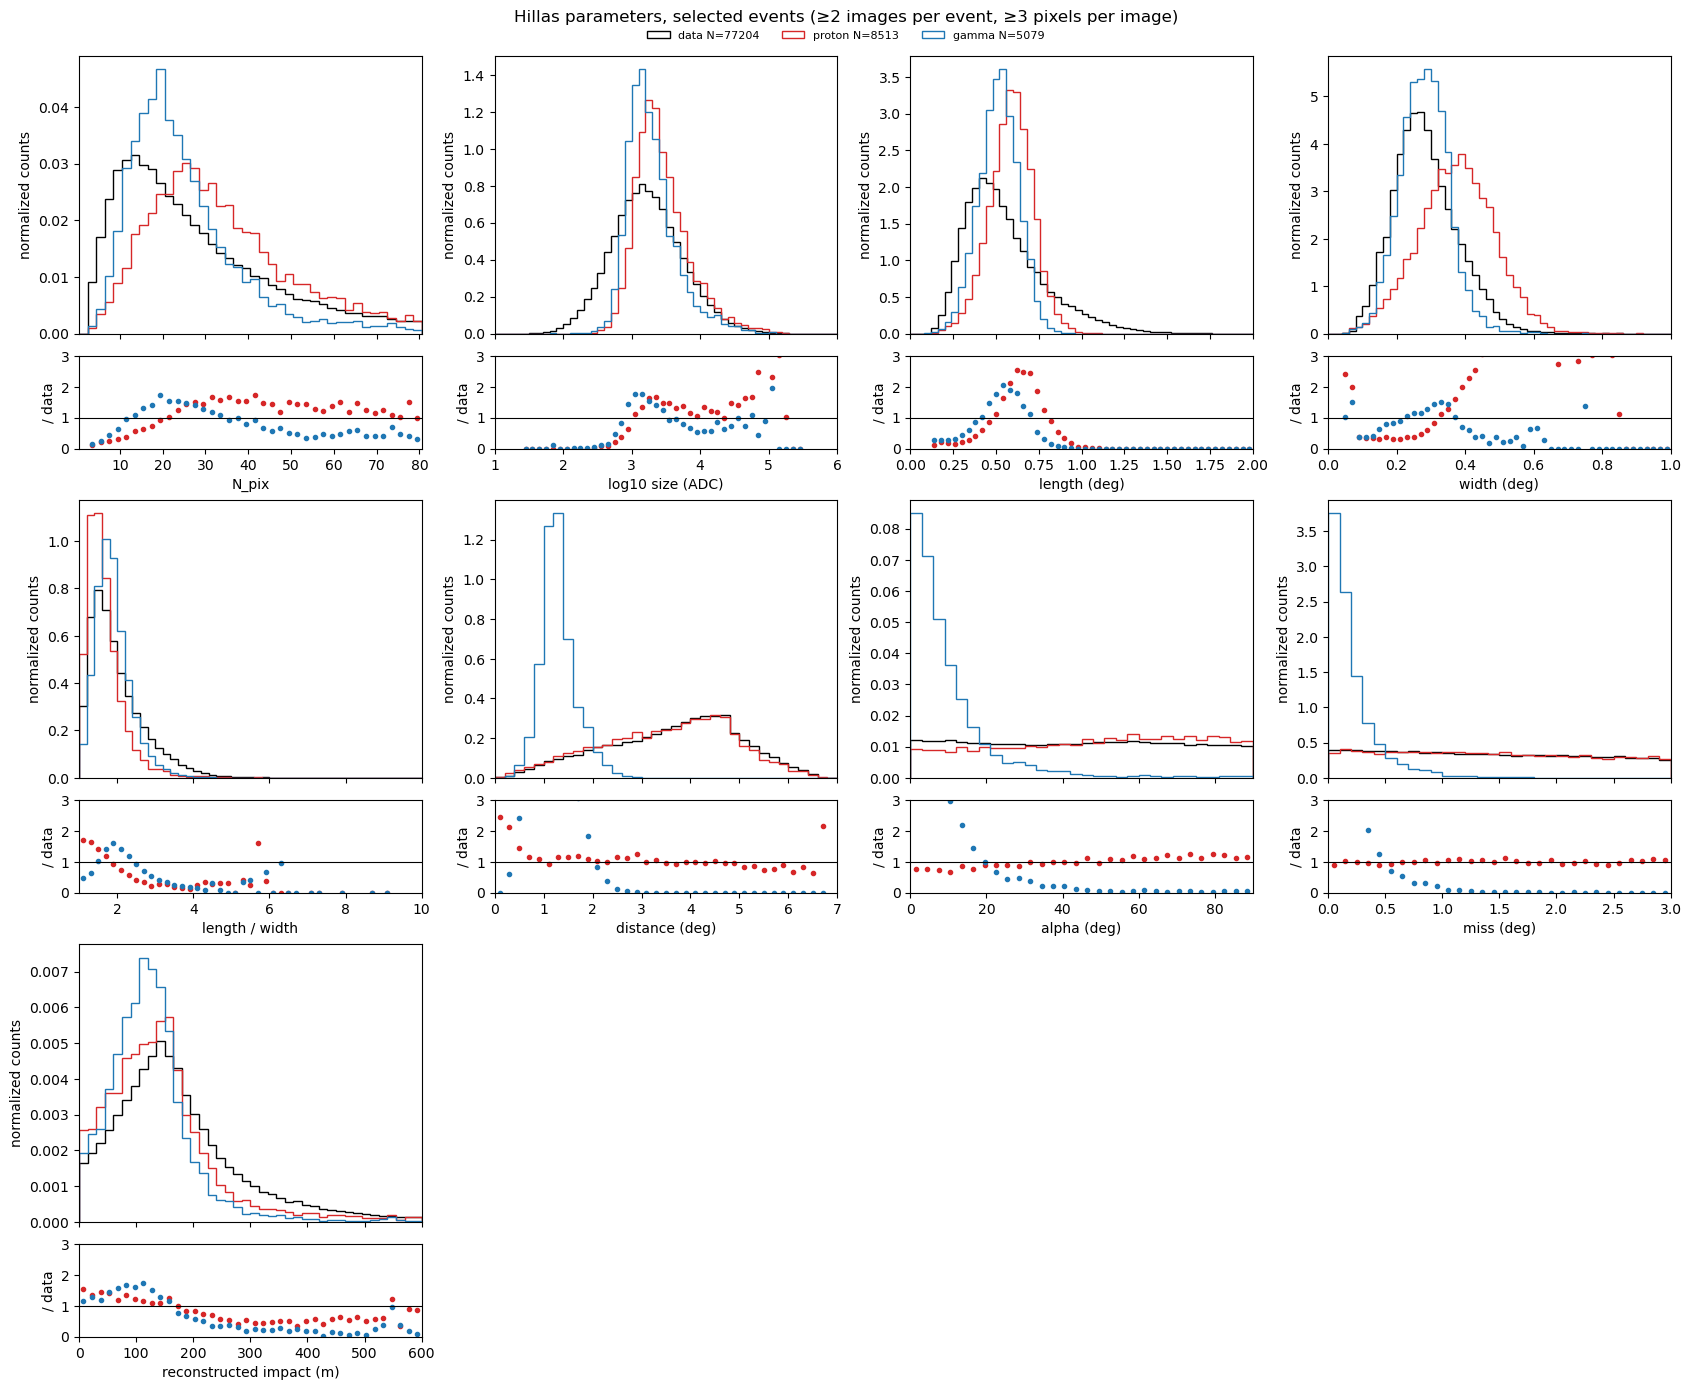

In [11]:
plot_hists(arrays, HILLAS_PARAMS, f"Hillas parameters, selected events ({SELECTED})")

In [12]:
pd.concat({label: array[["N_pix", "size", "length", "width", "length_width", "distance", "alpha", "impact_reco"]].describe() for label, array in arrays.items()}, axis=1)

data                                                           \
              N_pix           size        length         width  length_width   
count  77204.000000   77204.000000  77204.000000  77204.000000  77204.000000   
mean      31.840941    3687.762124      0.552864      0.285255      1.993544   
std       29.418982    7978.910857      0.237220      0.096227      0.726968   
min        3.000000      25.963859      0.127674      0.051544      1.001123   
25%       14.000000     740.672527      0.382671      0.219313      1.466611   
50%       24.000000    1585.910217      0.504340      0.274590      1.804817   
75%       40.000000    3571.640432      0.671251      0.341268      2.334914   
max      862.000000  305865.879437      2.806017      2.716495     10.370931   

                                                       proton                 \
           distance         alpha    impact_reco        N_pix           size   
count  77204.000000  77204.000000   77196.000000  8513.000000    8513.000000   
mean       3.644748     44.298400     313.634116    38.208975    5084.195568   
std        1.339995     26.035206    3419.699623    26.270394   10173.133868   
min        0.033038      0.002659       0.006647     3.000000     256.948459   
25%        2.677981     21.392548     101.010365    22.000000    1486.102759   
50%        3.811840     44.598056     157.839660    32.000000    2365.880309   
75%        4.638403     66.577526     237.842209    46.000000    4491.840050   
max        6.677195     89.999792  336095.621600   291.000000  190981.861941   

       ...                                   gamma                 \
       ...        alpha   impact_reco        N_pix           size   
count  ...  8513.000000   8513.000000  5079.000000    5079.000000   
mean   ...    48.289514    294.801078    26.435519    3278.173625   
std    ...    25.457133   2115.846508    17.850770    6574.264091   
min    ...     0.009979      0.018676     3.000000      68.212780   
25%    ...    27.011799     81.132639    16.000000    1103.411693   
50%    ...    50.535352    135.292534    22.000000    1674.950855   
75%    ...    69.977539    189.701992    31.000000    2898.844581   
max    ...    89.997499  93383.666261   279.000000  122017.151099   

                                                                        \
            length        width length_width     distance        alpha   
count  5079.000000  5079.000000  5079.000000  5079.000000  5079.000000   
mean      0.514786     0.281599     1.897451     1.297044    10.225455   
std       0.114364     0.071501     0.500601     0.359109    12.183951   
min       0.096209     0.052826     1.017120     0.265188     0.000101   
25%       0.440603     0.233823     1.571018     1.069596     2.935066   
50%       0.517218     0.281363     1.819430     1.249561     6.538250   
75%       0.592896     0.327458     2.124189     1.465737    12.779447   
max       0.941023     0.744909     8.253421     3.544919    89.841823   

                      
         impact_reco  
count    5079.000000  
mean      219.175950  
std      2554.389254  
min         0.029942  
25%        79.775266  
50%       118.824591  
75%       157.453862  
max    122324.159811  

[8 rows x 24 columns]

## Per telescope

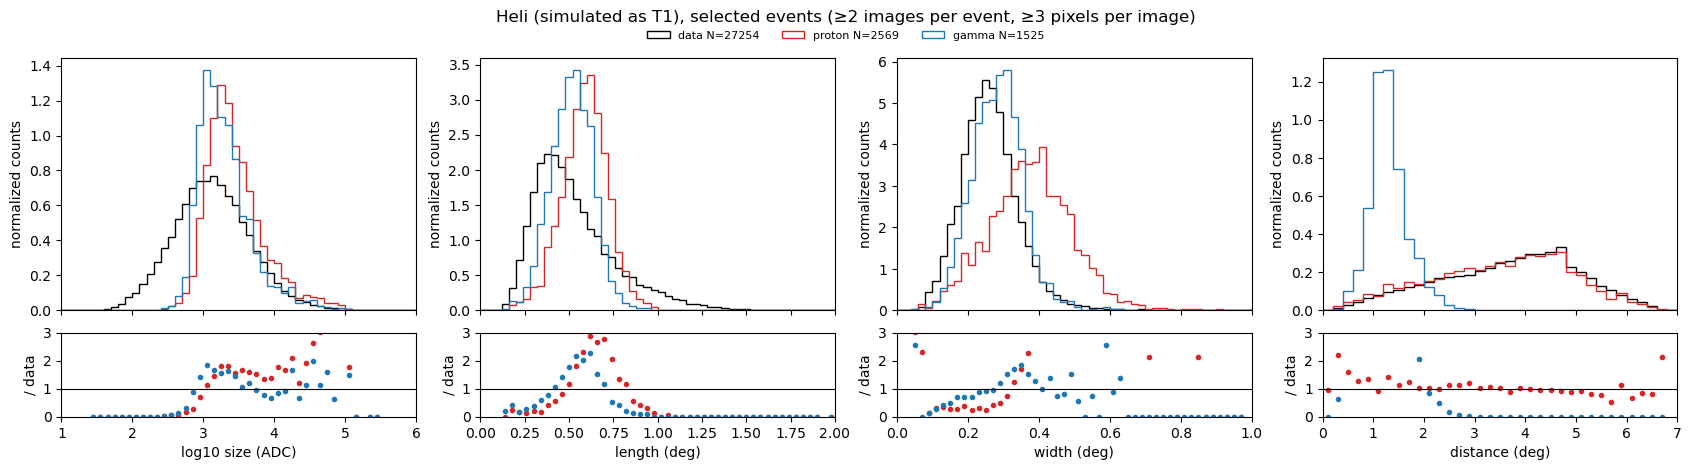

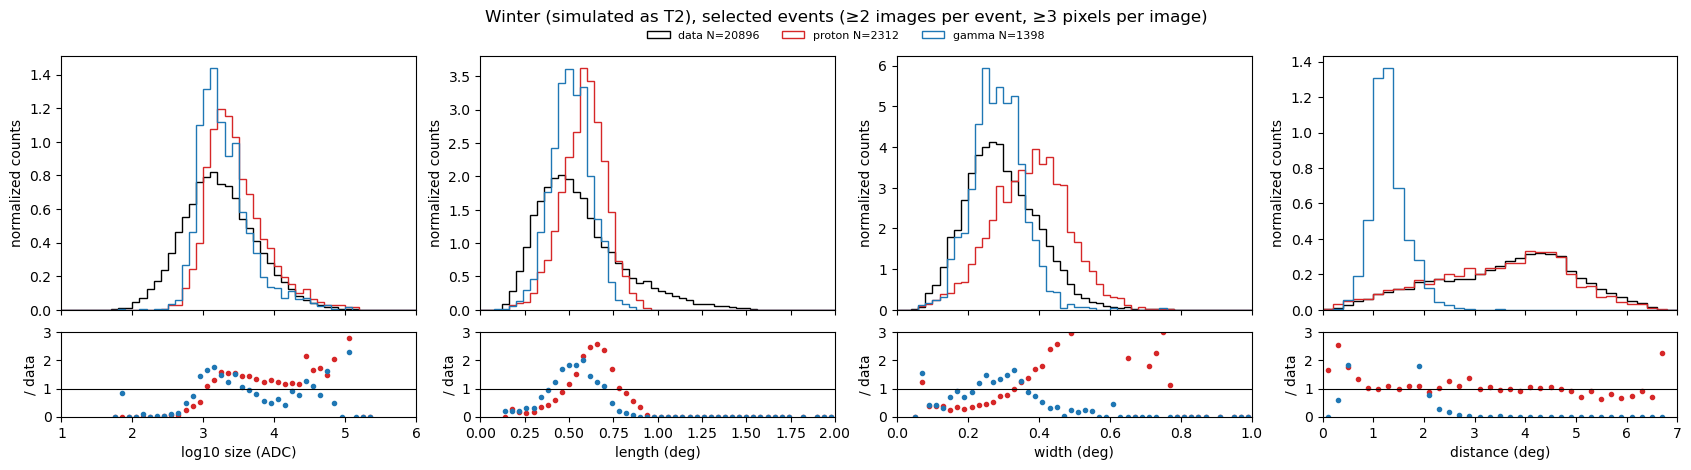

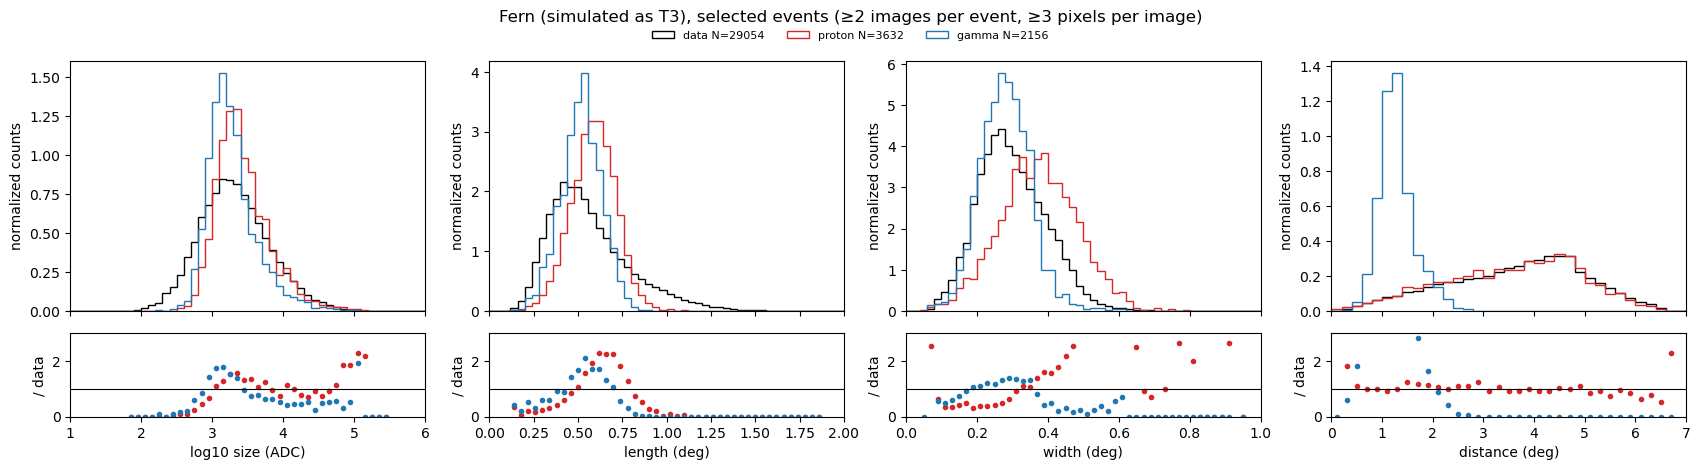

In [13]:
for name in TELESCOPES:
    plot_hists(
        {label: array[array.Telescope == name] for label, array in arrays.items()},
        {column: HILLAS_PARAMS[column] for column in ["log10_size", "length", "width", "distance"]},
        f"{name} (simulated as {SIM_TELESCOPES[name]}), selected events ({SELECTED})",
    )

## Profiles
Mean of one parameter in bins of another for the selected events, with its error.

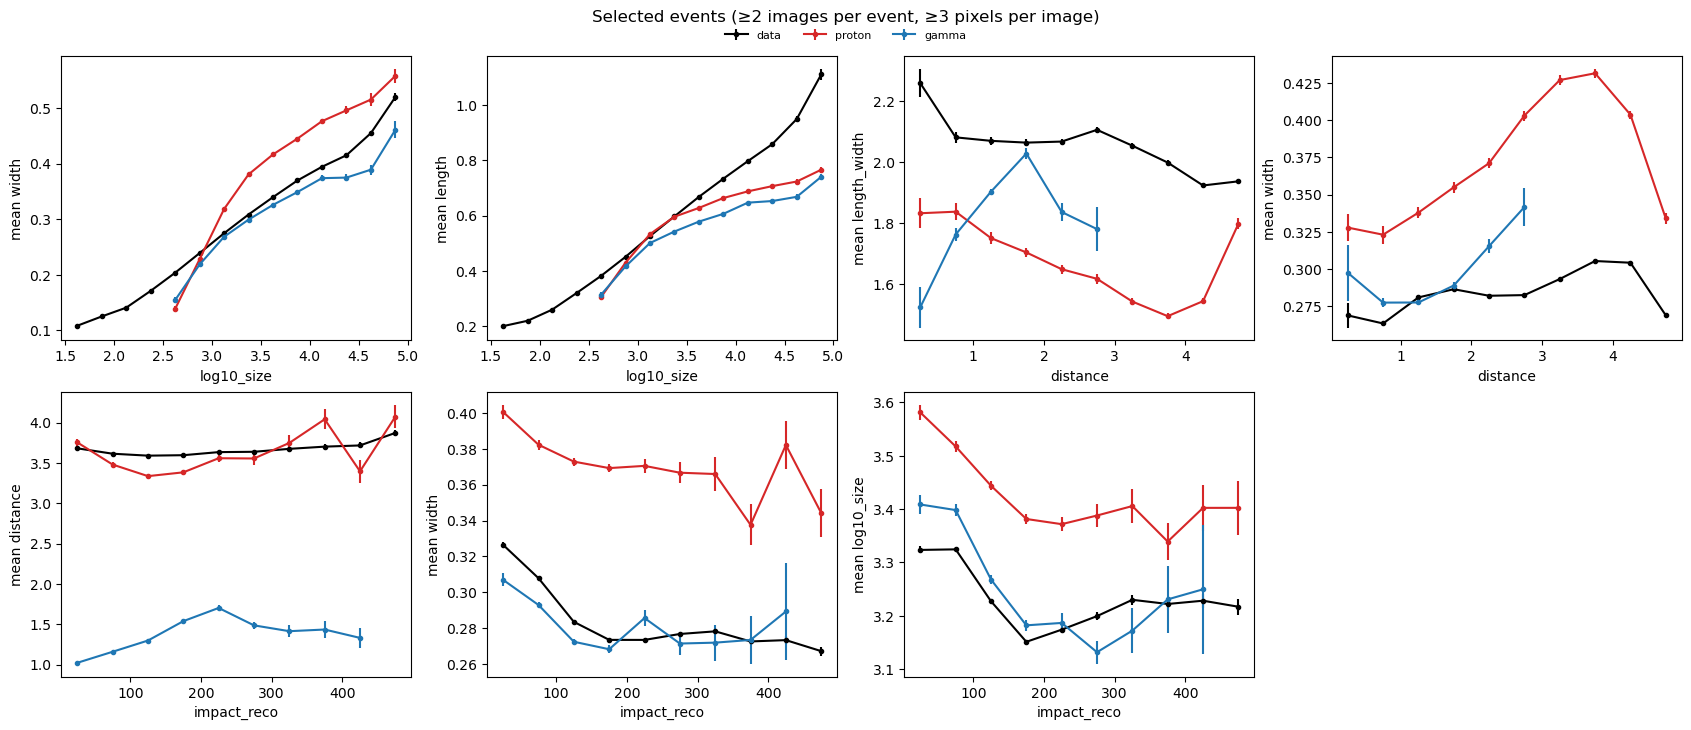

In [14]:
PROFILES = [ # (x, y, x bin edges): mean y in bins of x
    ("log10_size", "width", np.linspace(1.5, 5, 15)),
    ("log10_size", "length", np.linspace(1.5, 5, 15)),
    ("distance", "length_width", np.linspace(0, 5, 11)),
    ("distance", "width", np.linspace(0, 5, 11)),
    ("impact_reco", "distance", np.linspace(0, 500, 11)),
    ("impact_reco", "width", np.linspace(0, 500, 11)),
    ("impact_reco", "log10_size", np.linspace(0, 500, 11)),
]
plot_profiles(arrays, PROFILES, f"Selected events ({SELECTED})")

# Mean scaled width and length
Lookup tables of `LOOKUP_SAMPLE`'s weighted median and sigma (its 84% - 16% range, twice a Gaussian's sigma) of width and length per bin of `LOOKUP_X` and `LOOKUP_Y`, interpolated between bin centers and applied to every sample. `MSCWT` and `MSCWTSigma` are each image's expected width and its sigma from the tables, and its `scaled_width` is (width - `MSCWT`) / `MSCWTSigma`. Each event's mean scaled width, `MSCW`, is the mean of its images' `scaled_width` weighted by (`MSCWT` / `MSCWTSigma`)²; the same for length (`MSCLT`, `MSCLTSigma`, `scaled_length`, `MSCL`). Images outside the tables (or in bins with too few images) are left out. `LOOKUP_SAMPLE`'s values are out-of-fold: each quarter of its events uses tables of the other three quarters, so none is scaled by tables it helped make; the other samples use the tables of all of it, which are the ones shown.

In [15]:
def lookup_bins(images):
    """each image's (LOOKUP_X, LOOKUP_Y) bin, -1 outside LOOKUP_X_BINS, LOOKUP_Y_BINS"""
    return pd.DataFrame({
        "xi": pd.cut(images[LOOKUP_X], LOOKUP_X_BINS, labels=False).fillna(-1).astype(int),
        "yi": pd.cut(images[LOOKUP_Y], LOOKUP_Y_BINS, labels=False).fillna(-1).astype(int),
    })

def lookup_table(images, column, min_images=10):
    """weighted median of column and sigma, its 84% - 16% range, per (LOOKUP_X, LOOKUP_Y) bin with at least min_images images"""
    images = pd.concat([images[[column, "weight"]], lookup_bins(images)], axis=1).dropna()
    images = images[(images.xi >= 0) & (images.yi >= 0)]
    def quantiles(group):
        group = group.sort_values(column)
        low, median, high = np.interp([0.16, 0.5, 0.84], group.weight.cumsum() / group.weight.sum(), group[column])
        return pd.Series({"median": median, "sigma": high - low, "n": len(group)})
    table = images.groupby(["xi", "yi"])[[column, "weight"]].apply(quantiles)
    return table[table.n >= min_images]

def interpolate_between(value1, center1, value2, center2, x):
    """linear interpolation between two bins; with one NaN, the other bin's value if x is closer to it, else NaN"""
    fraction1 = 1 - (x - center1) / (center2 - center1)
    both = fraction1 * value1 + (1 - fraction1) * value2
    both = np.where(np.isnan(value2) & (fraction1 > 0.5), value1, both)
    return np.where(np.isnan(value1) & (fraction1 < 0.5), value2, both)

def from_table(images, table, key):
    """each image's key of table, interpolated between bin centers, first in LOOKUP_Y and then LOOKUP_X; NaN outside it"""
    n_x, n_y = len(LOOKUP_X_BINS) - 1, len(LOOKUP_Y_BINS) - 1
    grid = np.pad(table[key].unstack().reindex(index=range(n_x), columns=range(n_y)).to_numpy(dtype=float), 1, constant_values=np.nan) # bin i is grid[i + 1]
    x_centers = (LOOKUP_X_BINS[1:] + LOOKUP_X_BINS[:-1]) / 2
    y_centers = (LOOKUP_Y_BINS[1:] + LOOKUP_Y_BINS[:-1]) / 2
    x_centers = np.r_[2*x_centers[0] - x_centers[1], x_centers, 2*x_centers[-1] - x_centers[-2]]
    y_centers = np.r_[2*y_centers[0] - y_centers[1], y_centers, 2*y_centers[-1] - y_centers[-2]]
    bins = lookup_bins(images)
    xi, yi = bins.xi.to_numpy(), bins.yi.to_numpy()
    x, y = images[LOOKUP_X].to_numpy(), images[LOOKUP_Y].to_numpy()
    inside = (xi >= 0) & (yi >= 0)
    # the bins below each image's center: bin - 1 if it is below its bin's center
    i = np.where(inside, xi + 1 - (x < x_centers[np.where(inside, xi + 1, 0)]), 0)
    j = np.where(inside, yi + 1 - (y < y_centers[np.where(inside, yi + 1, 0)]), 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        in_y = [interpolate_between(grid[i + k, j], y_centers[j], grid[i + k, j + 1], y_centers[j + 1], y) for k in (0, 1)]
        values = interpolate_between(in_y[0], x_centers[i], in_y[1], x_centers[i + 1], x)
    # no interpolation in the last bins
    last = inside & ((xi == n_x - 1) | (yi == n_y - 1))
    values[last] = grid[xi[last] + 1, yi[last] + 1]
    values[~inside] = np.nan
    return values

def out_of_fold_expected(column):
    """{label: (each image's expected column and sigma)}, LOOKUP_SAMPLE's from tables of its other events, the others' from tables of all of it"""
    lookup_images = arrays[LOOKUP_SAMPLE]
    expected, sigma = np.full(len(lookup_images), np.nan), np.full(len(lookup_images), np.nan)
    for fit, apply in GroupKFold(4).split(lookup_images, groups=lookup_images.Event):
        table = lookup_table(lookup_images.iloc[fit], column)
        expected[apply], sigma[apply] = from_table(lookup_images.iloc[apply], table, "median"), from_table(lookup_images.iloc[apply], table, "sigma")
    results = {label: (from_table(array, tables[column], "median"), from_table(array, tables[column], "sigma")) for label, array in arrays.items() if label != LOOKUP_SAMPLE}
    results[LOOKUP_SAMPLE] = expected, sigma
    return results

def scale(array, column, expected, sigma):
    """(array's column - expected) / sigma, and each image's weight (expected / sigma)^2; NaN without a positive expected and sigma"""
    good = (expected > 0) & (sigma > 0)
    expected, sigma = np.where(good, expected, np.nan), np.where(good, sigma, np.nan)
    return (array[column].to_numpy() - expected) / sigma, (expected / sigma)**2

def mean_scaled(array, scaled, weight):
    """per event, the mean of its images' scaled values weighted by weight"""
    return (array[scaled] * array[weight]).groupby(array.Event).sum() / array[weight].groupby(array.Event).sum()

def event_parameters(array):
    """
    one row per event: n_images, log10_total_size (of its images' summed size), max_distance (of its farthest
    image), weight, and MSCW, MSCL: the means of its images' scaled_width and scaled_length, each weighted by
    (expected / sigma)^2 (images outside the lookup tables left out, NaN if all are)
    """
    grouped = array.groupby("Event")
    return pd.DataFrame({
        "n_images": grouped.size(),
        "log10_total_size": np.log10(grouped["size"].sum()),
        "max_distance": grouped.distance.max(),
        "MSCW": mean_scaled(array, "scaled_width", "width_weight"),
        "MSCL": mean_scaled(array, "scaled_length", "length_weight"),
        "weight": grouped.weight.first(),
    })

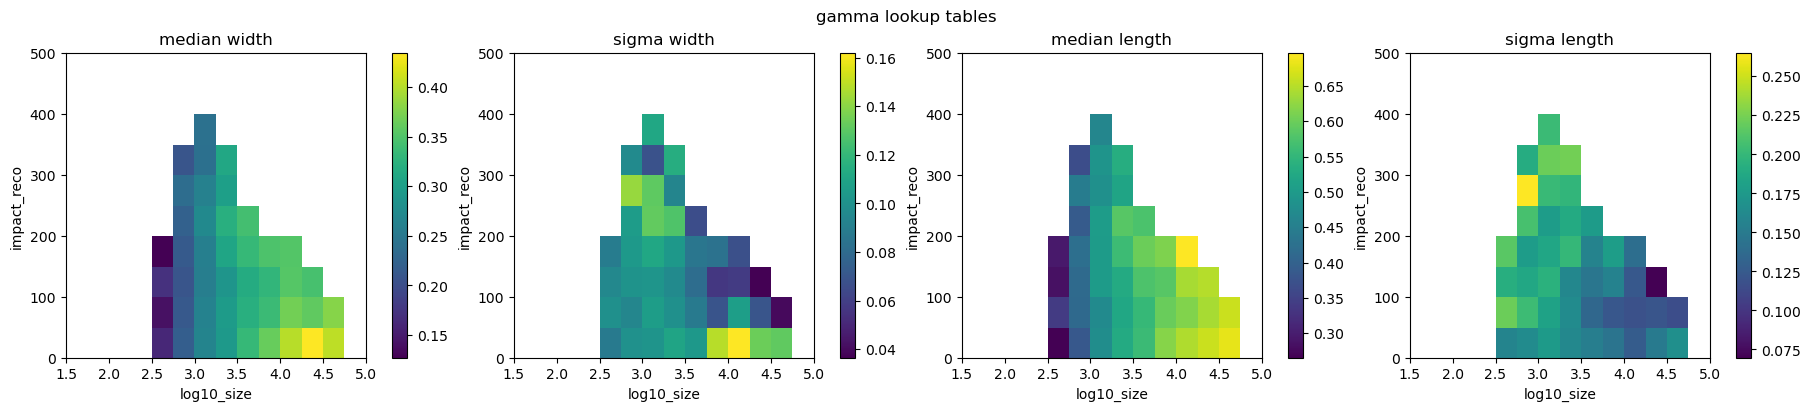

In [16]:
tables = {column: lookup_table(arrays[LOOKUP_SAMPLE], column) for column in ["width", "length"]}
for column, prefix in {"width": "MSCW", "length": "MSCL"}.items():
    expected = out_of_fold_expected(column)
    for label, array in arrays.items():
        array[f"{prefix}T"], array[f"{prefix}TSigma"] = expected[label]
        array[f"scaled_{column}"], array[f"{column}_weight"] = scale(array, column, *expected[label])

fig, axs = plt.subplots(1, 4, figsize=(18, 4), layout="constrained")
for ax, (column, key) in zip(axs, [(column, key) for column in tables for key in ("median", "sigma")]):
    grid = tables[column][key].unstack().reindex(index=range(len(LOOKUP_X_BINS) - 1), columns=range(len(LOOKUP_Y_BINS) - 1))
    im = ax.imshow(grid.T, origin="lower", aspect="auto", extent=[LOOKUP_X_BINS[0], LOOKUP_X_BINS[-1], LOOKUP_Y_BINS[0], LOOKUP_Y_BINS[-1]])
    fig.colorbar(im, ax=ax)
    ax.set(xlabel=LOOKUP_X, ylabel=LOOKUP_Y, title=f"{key} {column}")
fig.suptitle(f"{LOOKUP_SAMPLE} lookup tables")
plt.show()
events = {label: event_parameters(array) for label, array in arrays.items()}

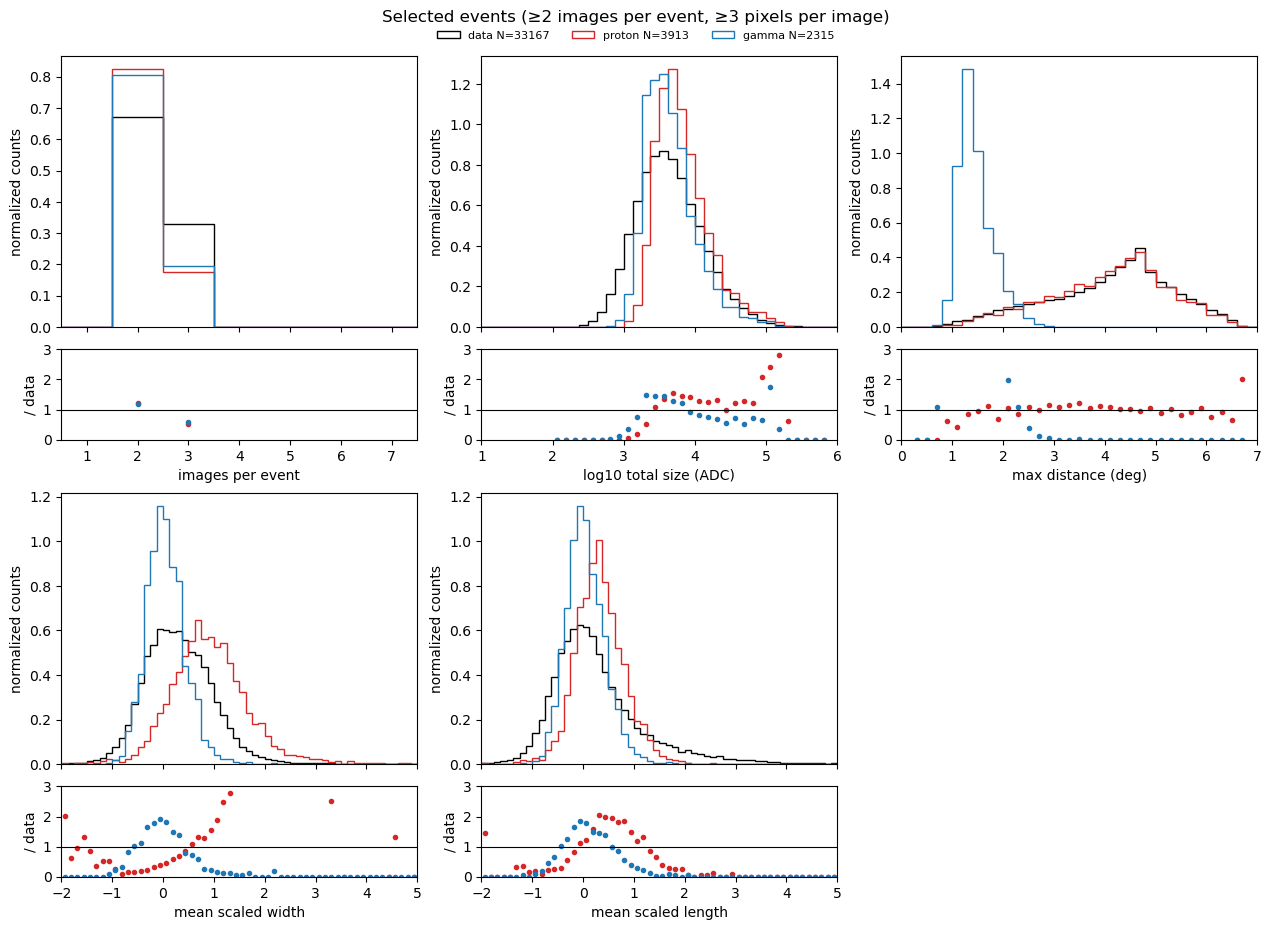

In [17]:
plot_hists(events, EVENT_PARAMS, f"Selected events ({SELECTED})", n_cols=3)

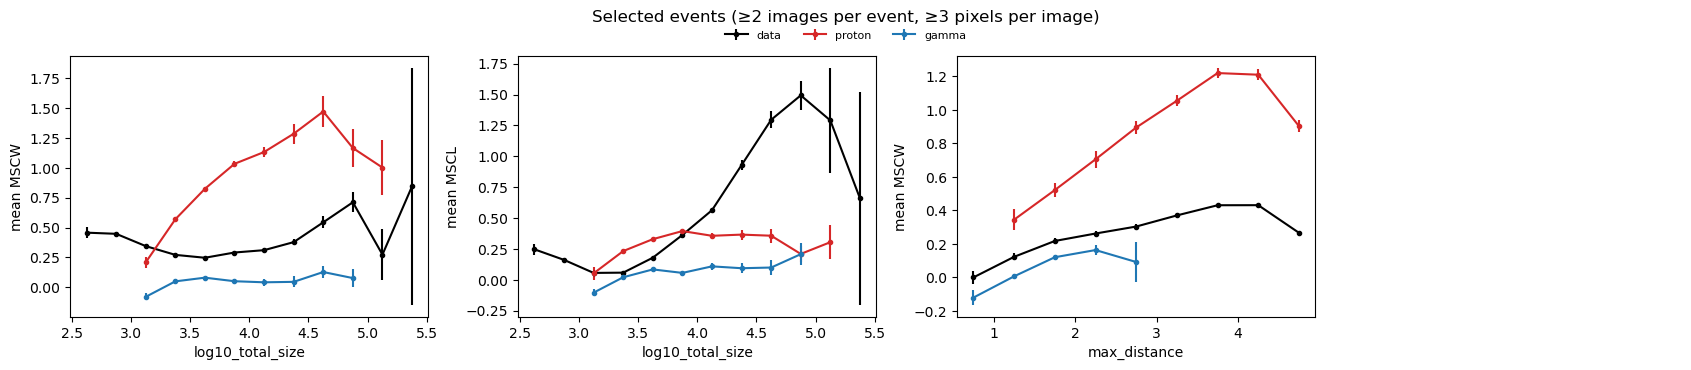

In [18]:
plot_profiles(events, [
    ("log10_total_size", "MSCW", np.linspace(2.5, 5.5, 13)),
    ("log10_total_size", "MSCL", np.linspace(2.5, 5.5, 13)),
    ("max_distance", "MSCW", np.linspace(0, 5, 11)),
], f"Selected events ({SELECTED})")

In [19]:
# the fraction of each sample a gamma/hadron cut keeps (e.g. from gamma_hadron.ipynb), as a pandas query on the events
SELECTION = "MSCW < 0.5"
pd.DataFrame({label: {"events": len(e), "kept": e.query(SELECTION).weight.sum() / e.weight.sum()} for label, e in events.items()}).T

,events,kept
data,33167.0,0.545723
proton,3913.0,0.258881
gamma,2315.0,0.850108
